# FH Entanglement Structure and Circuit Complexity

Characterise the ground-state entanglement of `FermiHubbard1D` as a function of system size
and JW ordering, then estimate the circuit depth needed to prepare those ground states.

**Functions introduced:** `entanglement_entropy`, `entanglement_profile`, `entanglement_depth`  
**Sections:**
1. Entanglement profile for stacked vs interleaved orderings
2. Scaling of maximum bipartite entanglement
3. Entanglement depth lower bound
4. Preparation depth via environment sweep
5. Ordering comparison

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from qaravan.applications import ground_state
from qaravan.applications.quantum_info import (
    entanglement_entropy,
    entanglement_profile,
    entanglement_depth,
)
from qaravan.applications.compilation import environment_state_prep
from qaravan.applications.circuit_library import brickwall_skeleton
from qaravan.applications.run_context import RunContext
from qaravan.backends.statevector import Statevector
from qaravan.core.fermions import FermionicEncoding
from qaravan.core.hamiltonians import FermiHubbard1D, interleaved_mode_order
from qaravan.plot import set_style

set_style()


def fh_encoding(num_fermions: int, ordering: str) -> FermionicEncoding:
    """The two named qubit layouts, as FermionicEncodings."""
    mode_order = None if ordering == "stacked" else interleaved_mode_order(num_fermions)
    return FermionicEncoding(
        "jordan_wigner", num_modes=2 * num_fermions, mode_order=mode_order
    )


def fh_ground_state(num_fermions: int, t: float, U: float, ordering: str, mu: float = 0.0):
    """Bare FermiHubbard1D -> encoded Hamiltonian -> ground state, for one ordering."""
    fh = FermiHubbard1D(num_fermions, t=t, U=U, mu=mu)
    ham = fh.encode(fh_encoding(num_fermions, ordering))
    return ground_state(ham, fixed_particle_number=num_fermions)

## 1. Entanglement profile

For each contiguous bipartition $[0 \ldots k] \mid [k+1 \ldots n-1]$, compute
$S_k = -\mathrm{Tr}[\rho_A \log \rho_A]$.

Parameters: $t = U = 1$, half-filling ($N_{\uparrow} = N_{\downarrow} = L/2$).

In [ ]:
sizes = [2, 3, 4]
orderings = ["stacked", "interleaved"]

ground_states = {}
for nf in sizes:
    for ordering in orderings:
        ground_states[(nf, ordering)] = fh_ground_state(nf, t=1.0, U=1.0, ordering=ordering)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
colors = ["C0", "C1", "C2"]

for ax, ordering in zip(axes, orderings):
    for nf, color in zip(sizes, colors):
        gs = ground_states[(nf, ordering)]
        profile = entanglement_profile(gs)
        n = gs.num_sites
        ax.plot(range(n - 1), profile, "o-", color=color, label=f"$L={nf}$")
    ax.axhline(np.log(2), ls="--", color="grey", lw=0.8, label="$\\log 2$")
    ax.set_xlabel("Cut $k$")
    ax.set_title(ordering)
    ax.legend()

axes[0].set_ylabel("$S_k$")
fig.suptitle("FH ground-state entanglement profile ($t=U=1$, half-filling)")
plt.tight_layout()
plt.show()

**Reading the plot:** Stacked places all spin-up qubits first, then all spin-down.
The on-site Hubbard interaction becomes long-range ZZ, driving large entropy at
cuts that separate the two spin sectors.
Interleaved alternates $\uparrow_j, \downarrow_j$, making the on-site term local
but giving hopping a weight-3 JW string (XZX + YZY).

## 2. Scaling of maximum bipartite entanglement

Plot $\max_k S_k$ versus $L$ for $L = 2, \ldots, 6$ (up to 12 qubits).

In [ ]:
all_sizes = list(range(2, 8))
U_vals = [1.0, 10.0]
orderings = ["stacked", "interleaved"]

# Cache ground states by (nf, ordering, U)
gs_cache = {}
for U in U_vals:
    for nf in all_sizes:
        for ordering in orderings:
            if (nf, ordering, U) not in gs_cache:
                gs_cache[(nf, ordering, U)] = fh_ground_state(nf, t=1.0, U=U, ordering=ordering)

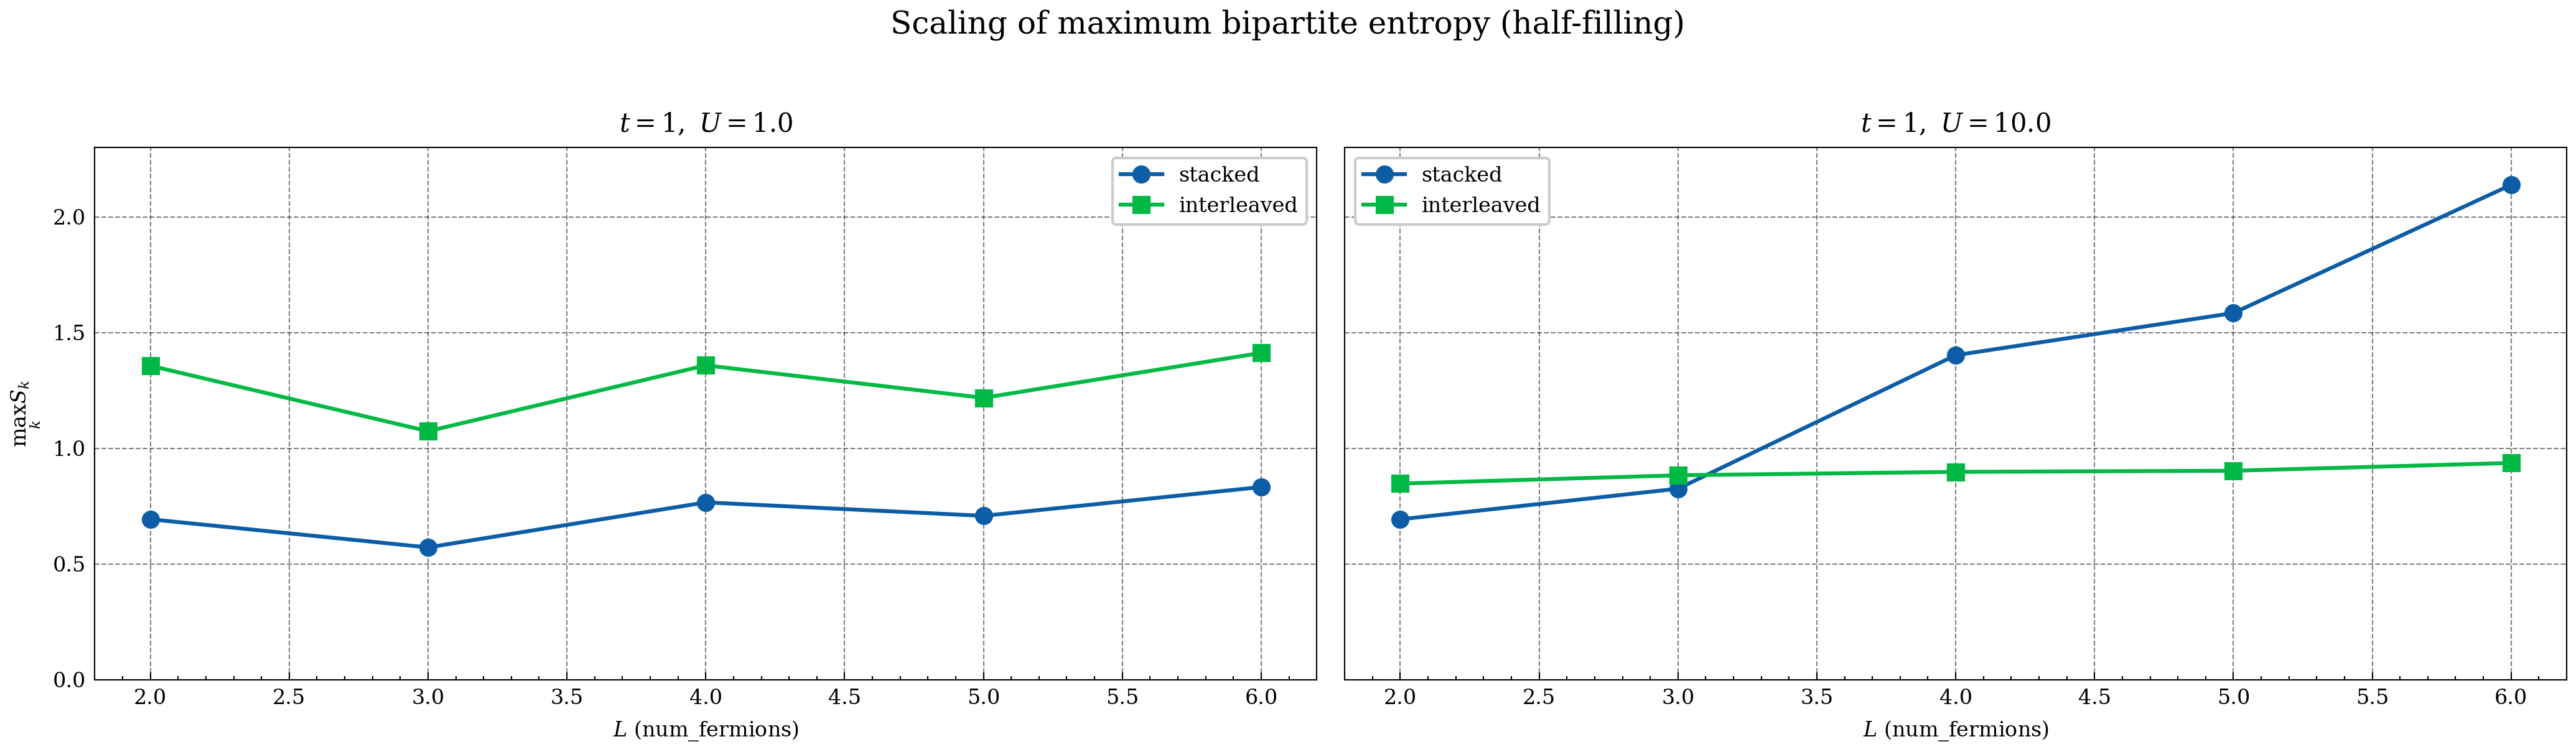

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, U in zip(axes, U_vals):
    for ordering, marker in zip(orderings, ["o", "s"]):
        max_S = [entanglement_profile(gs_cache[(nf, ordering, U)]).max() for nf in all_sizes]
        ax.plot(all_sizes, max_S, marker + "-", label=ordering)
    ax.set_xlabel("$L$ (num_fermions)")
    ax.set_title(f"$t=1,\\ U={U}$")
    ax.legend()
    ax.set_ylim(0, 2.3)

axes[0].set_ylabel(r"$\max_k S_k$")
fig.suptitle("Scaling of maximum bipartite entropy (half-filling)", y=1.02)
plt.tight_layout()
plt.show()

**Note:** At $t = U$ and half-filling the 1D Hubbard model is at the Mott transition
(gapless charge and spin sectors, central charge $c = 2$).
Entropy grows logarithmically: $S \sim \frac{c}{3} \log L$.
The range $L = 2 \ldots 6$ is too small to fit the log cleanly but the trend is visible.

## 3. Entanglement depth lower bound

For a depth-$d$ nearest-neighbour brickwall (counting **individual gate layers** —
even and odd sublayers each count as 1), entropy across any bipartition is at most
$d \log 2$.  
Therefore $d_{\min} = \lceil \max_k S_k / \log 2 \rceil$ is a lower bound on the
number of 2-qubit gate layers needed.

In [ ]:
print(f"{'L':>4}  {'stacked depth':>14}  {'interleaved depth':>18}")
print("-" * 42)
for nf in all_sizes:
    depths = {
        ordering: entanglement_depth(gs_cache[(nf, ordering, 1.0)]) for ordering in orderings
    }
    print(f"{nf:>4}  {depths['stacked']:>14}  {depths['interleaved']:>18}")

## 4. Preparation depth via environment sweep

**Circuit construction:** `brickwall_skeleton(n)` returns one full alternating period —
an even sublayer then an odd sublayer — already circuit depth **2**.
Repeating it $r$ times gives true depth $2r$.
`environment_state_prep` with `skeleton=brickwall_skeleton(n) * r` initialises
a circuit of $|\text{skeleton}|$ generic 2-qubit unitaries and optimises them via SVD.

We record the minimum **true circuit depth** (= $2r$) at which fidelity $\geq 0.99$
after sweep convergence, and compare it to the lower bound from `entanglement_depth`
(both in units of gate layers).

Scope: $L = 2, 3, 4$.

In [5]:
FIDELITY_TARGET = 0.99
MAX_REPEATS = 8   # true depth up to 2 * MAX_REPEATS = 16
SWEEP_SIZES = [2, 3, 4]
ctx = RunContext(max_iter=300)

# prep_results[(nf, ordering)] = {"true_depth": int|None, "fidelity": float|None, "costs": list|None}
prep_results = {}

for nf in SWEEP_SIZES:
    n = 2 * nf
    init = Statevector(bitstring="0" * n)
    for ordering in orderings:
        gs = ground_states[(nf, ordering)]
        found = {"true_depth": None, "fidelity": None, "costs": None}
        for repeat in range(1, MAX_REPEATS + 1):
            skel = brickwall_skeleton(n) * repeat
            _, costs = environment_state_prep(gs, init, skeleton=skel, context=ctx)
            fidelity = 1.0 - costs[-1]
            if fidelity >= FIDELITY_TARGET:
                found = {"true_depth": 2 * repeat, "fidelity": fidelity, "costs": costs}
                break
        prep_results[(nf, ordering)] = found
        status = (
            f"true_depth={found['true_depth']}, F={found['fidelity']:.4f}"
            if found["true_depth"] else f"not reached in true_depth <= {2*MAX_REPEATS}"
        )
        print(f"nf={nf}, {ordering}: {status}")

nf=2, stacked: true_depth=2, F=0.9925
nf=2, interleaved: true_depth=2, F=0.9925
nf=3, stacked: true_depth=2, F=0.9938


nf=3, interleaved: true_depth=4, F=0.9967


nf=4, stacked: true_depth=4, F=0.9904


nf=4, interleaved: true_depth=6, F=0.9934


In [6]:
# Both columns in units of single 2-qubit gate layers — comparison is fair.
print(f"{'L':>4}  {'ordering':>12}  {'ent. depth (LB)':>16}  {'prep depth (true)':>18}  {'fidelity':>9}")
print("-" * 66)
for nf in SWEEP_SIZES:
    for ordering in orderings:
        lb = entanglement_depth(ground_states[(nf, ordering)])
        r = prep_results[(nf, ordering)]
        d_str = str(r["true_depth"]) if r["true_depth"] else f">{2*MAX_REPEATS}"
        f_str = f"{r['fidelity']:.4f}" if r["fidelity"] else "—"
        print(f"{nf:>4}  {ordering:>12}  {lb:>16}  {d_str:>18}  {f_str:>9}")

   L      ordering   ent. depth (LB)   prep depth (true)   fidelity
------------------------------------------------------------------
   2       stacked                 1                   2     0.9925
   2   interleaved                 2                   2     0.9925
   3       stacked                 1                   2     0.9938
   3   interleaved                 2                   4     0.9967
   4       stacked                 2                   4     0.9904
   4   interleaved                 2                   6     0.9934


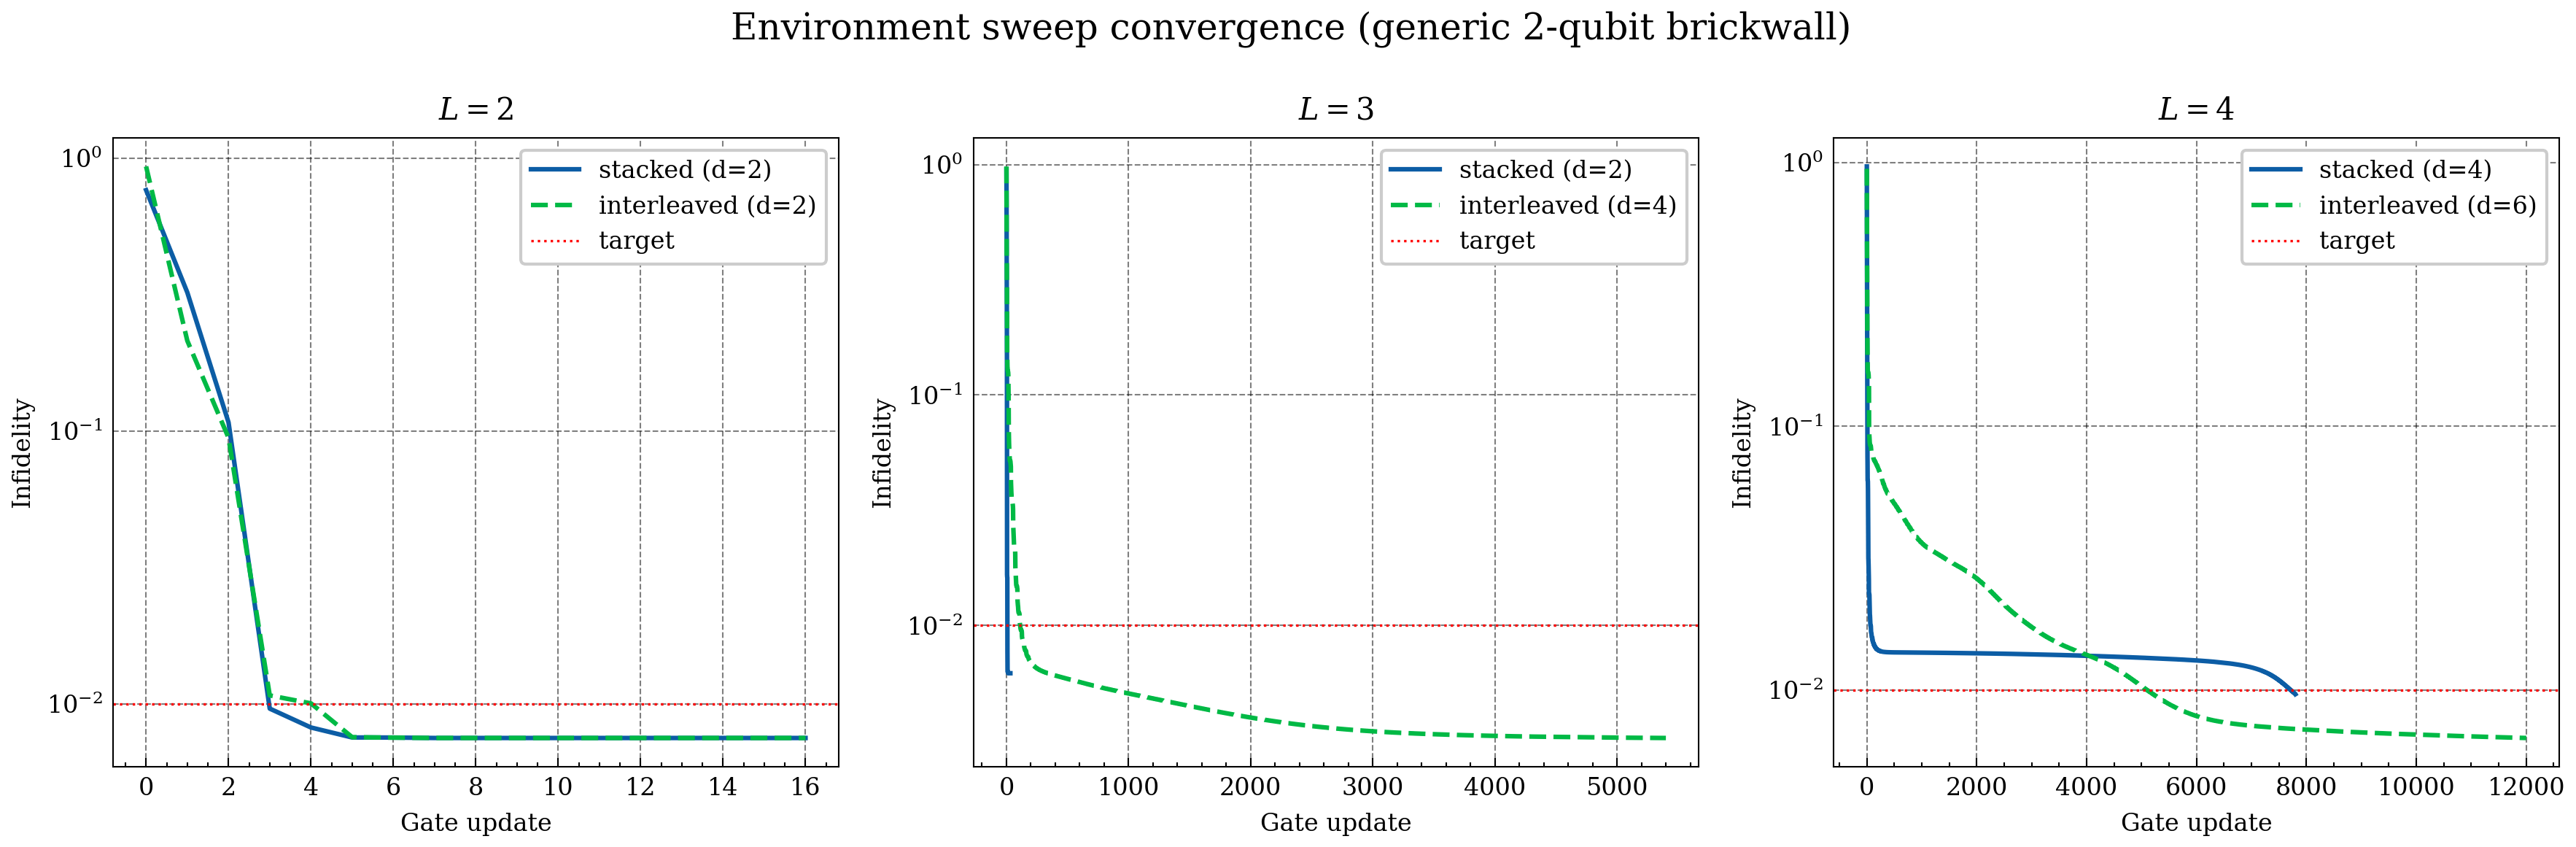

In [7]:
fig, axes = plt.subplots(1, len(SWEEP_SIZES), figsize=(12, 4), sharey=False)

for ax, nf in zip(axes, SWEEP_SIZES):
    for ordering, ls in zip(orderings, ["-", "--"]):
        r = prep_results[(nf, ordering)]
        if r["costs"] is not None:
            ax.semilogy(r["costs"], ls=ls, label=f"{ordering} (d={r['true_depth']})")
    ax.set_xlabel("Gate update")
    ax.set_ylabel("Infidelity")
    ax.set_title(f"$L={nf}$")
    ax.axhline(1 - FIDELITY_TARGET, color="red", lw=0.8, ls=":", label="target")
    ax.legend(fontsize=8)

fig.suptitle("Environment sweep convergence (generic 2-qubit brickwall)")
plt.tight_layout()
plt.show()

## 5. Ordering comparison

**Why do stacked and interleaved orderings give different entanglement profiles?**

The Jordan-Wigner transformation maps fermionic operators to qubit operators via:
$$c_j^\dagger \mapsto \left(\prod_{k<j} Z_k\right) \frac{X_j - iY_j}{2}$$

The JW string $\prod_{k<j} Z_k$ entangles qubit $j$ with all preceding qubits.
Its length — and how non-local the mapped operator is — depends on ordering.

**Stacked** ($[\uparrow_0, \uparrow_1, \ldots, \downarrow_0, \downarrow_1, \ldots]$):
- Same-spin hopping: JW string of length 1 within the $\uparrow$ block → weight-2 Pauli (XX + YY).
- On-site interaction $n_{j\uparrow} n_{j\downarrow}$: couples qubit $j$ to qubit $L+j$
  → **long-range ZZ**, peak entropy at cuts separating the two spin sectors.

**Interleaved** ($[\uparrow_0, \downarrow_0, \uparrow_1, \downarrow_1, \ldots]$):
- On-site interaction: couples adjacent qubits $2j$ and $2j+1$ → local ZZ.
- Same-spin hopping: JW string crosses the intervening $\downarrow_j$ qubit
  → weight-3 Pauli (XZX + YZY).

**Practical implication:** For a nearest-neighbour device, neither ordering is universally
better. The table above shows which ordering requires fewer true gate layers at $t = U = 1$.

In [ ]:
# Summary: max entropy, entanglement depth, and preparation depth (all L)
print("Summary (t=U=1, half-filling)")
print(f"{'L':>3}  {'ordering':>12}  {'max_S':>7}  {'ent_depth':>9}  {'prep_depth':>10}")
print("-" * 50)
for nf in all_sizes:
    for ordering in orderings:
        gs = gs_cache[(nf, ordering, 1.0)]
        max_s = entanglement_profile(gs).max()
        ed = entanglement_depth(gs)
        if nf in SWEEP_SIZES:
            r = prep_results[(nf, ordering)]
            pd_str = str(r["true_depth"]) if r["true_depth"] else f">{2*MAX_REPEATS}"
        else:
            pd_str = "—"
        print(f"{nf:>3}  {ordering:>12}  {max_s:>7.4f}  {ed:>9}  {pd_str:>10}")

# 6 fermions, half filling, interesting parameters

In [ ]:
nf, t, U = 6, 1.0, 1.0
n = 2 * nf

for ordering in ["interleaved"]:
    gs = fh_ground_state(nf, t=t, U=U, ordering=ordering)

    profile = entanglement_profile(gs)
    max_S = profile.max()
    ent_d = entanglement_depth(gs)
    print(f"\n{ordering}")
    print(f"  max_S = {max_S:.4f}  ({max_S/np.log(2):.3f} ebits)")
    print(f"  entanglement_depth = {ent_d} gate layers")

    init = Statevector(bitstring="0" * n)
    ctx = RunContext(max_iter=300)
    for repeat in range(1, 9):
        _, costs = environment_state_prep(gs, init, skeleton=brickwall_skeleton(n) * repeat, context=ctx)
        fidelity = 1.0 - costs[-1]
        print(f"  true_depth={2*repeat}: F={fidelity:.4f}", end="")
        if fidelity >= 0.99:
            print(f"  ← prep_depth = {2*repeat}")
            break
        print()
    else:
        print(f"\n  prep_depth > {2*8} (not converged)")


In [ ]:
nf, t, U = 7, 1.0, 1.0
n = 2 * nf

for ordering in ["interleaved"]:
    gs = fh_ground_state(nf, t=t, U=U, ordering=ordering)

    profile = entanglement_profile(gs)
    max_S = profile.max()
    ent_d = entanglement_depth(gs)
    print(f"\n{ordering}")
    print(f"  max_S = {max_S:.4f}  ({max_S/np.log(2):.3f} ebits)")
    print(f"  entanglement_depth = {ent_d} gate layers")

    init = Statevector(bitstring="0" * n)
    ctx = RunContext(max_iter=300)
    for repeat in range(1, 9):
        _, costs = environment_state_prep(gs, init, skeleton=brickwall_skeleton(n) * repeat, context=ctx)
        fidelity = 1.0 - costs[-1]
        print(f"  true_depth={2*repeat}: F={fidelity:.4f}", end="")
        if fidelity >= 0.99:
            print(f"  ← prep_depth = {2*repeat}")
            break
        print()
    else:
        print(f"\n  prep_depth > {2*8} (not converged)")


## 7. Purity and bond dimension at $U=0$

Moved verbatim from the Fermi-Hubbard devbook, where they sat under "free-fermionic limit" but
are really entanglement-structure results. **These cells still expect that notebook's imports
and `fh_encoding` helper** -- they need adapting before they will run here.

### Purity

Even though the ground state is the "same up to relabelling" in the two mode orderings in fermionic language, they are different in spin language. 

The ground state for free dimer with stacked ordering factorizes: 

$-0.5000|0101⟩ - 0.5000|0110⟩ - 0.5000|1001⟩ - 0.5000|1010⟩$ 

But the same state with interleaved order doesn't factorize because of the single minus sign:

$0.5000|0011⟩ - 0.5000|0110⟩ + 0.5000|1001⟩ + 0.5000|1100⟩$

In [14]:
num_fermionic_sites = 2
t = 1.0

# Ground state of each ordering at U=0
fh = FermiHubbard1D(num_fermionic_sites=num_fermionic_sites, t=t, U=0.0, mu=0.0, periodic=True)
sv_s = fermionic_ground_state(fh, fh_encoding(num_fermionic_sites, "stacked"), 
                              fixed_spin_numbers=(1,1))
sv_i = fermionic_ground_state(fh, fh_encoding(num_fermionic_sites, "interleaved"), 
                              fixed_spin_numbers=(1,1))

down_sites_stacked = list(range(num_fermionic_sites, 2 * num_fermionic_sites))
rho_down_s = sv_s.rdm(down_sites_stacked)
purity_s = np.trace(rho_down_s @ rho_down_s).real

# For interleaved, down-qubits are at odd indices
down_sites_interleaved = list(range(1, 2 * num_fermionic_sites, 2))
rho_down_i = sv_i.rdm(down_sites_interleaved)
purity_i = np.trace(rho_down_i @ rho_down_i).real

purities = [purity_s, purity_i]

print(f"Stacked  Tr[rho_down^2] = {purity_s:.10f}  (expected 1.0)")
print(f"Interleaved Tr[rho_down^2] = {purity_i:.10f}  (expected < 1)")

Stacked  Tr[rho_down^2] = 1.0000000000  (expected 1.0)
Interleaved Tr[rho_down^2] = 0.5000000000  (expected < 1)


### Bond dimension

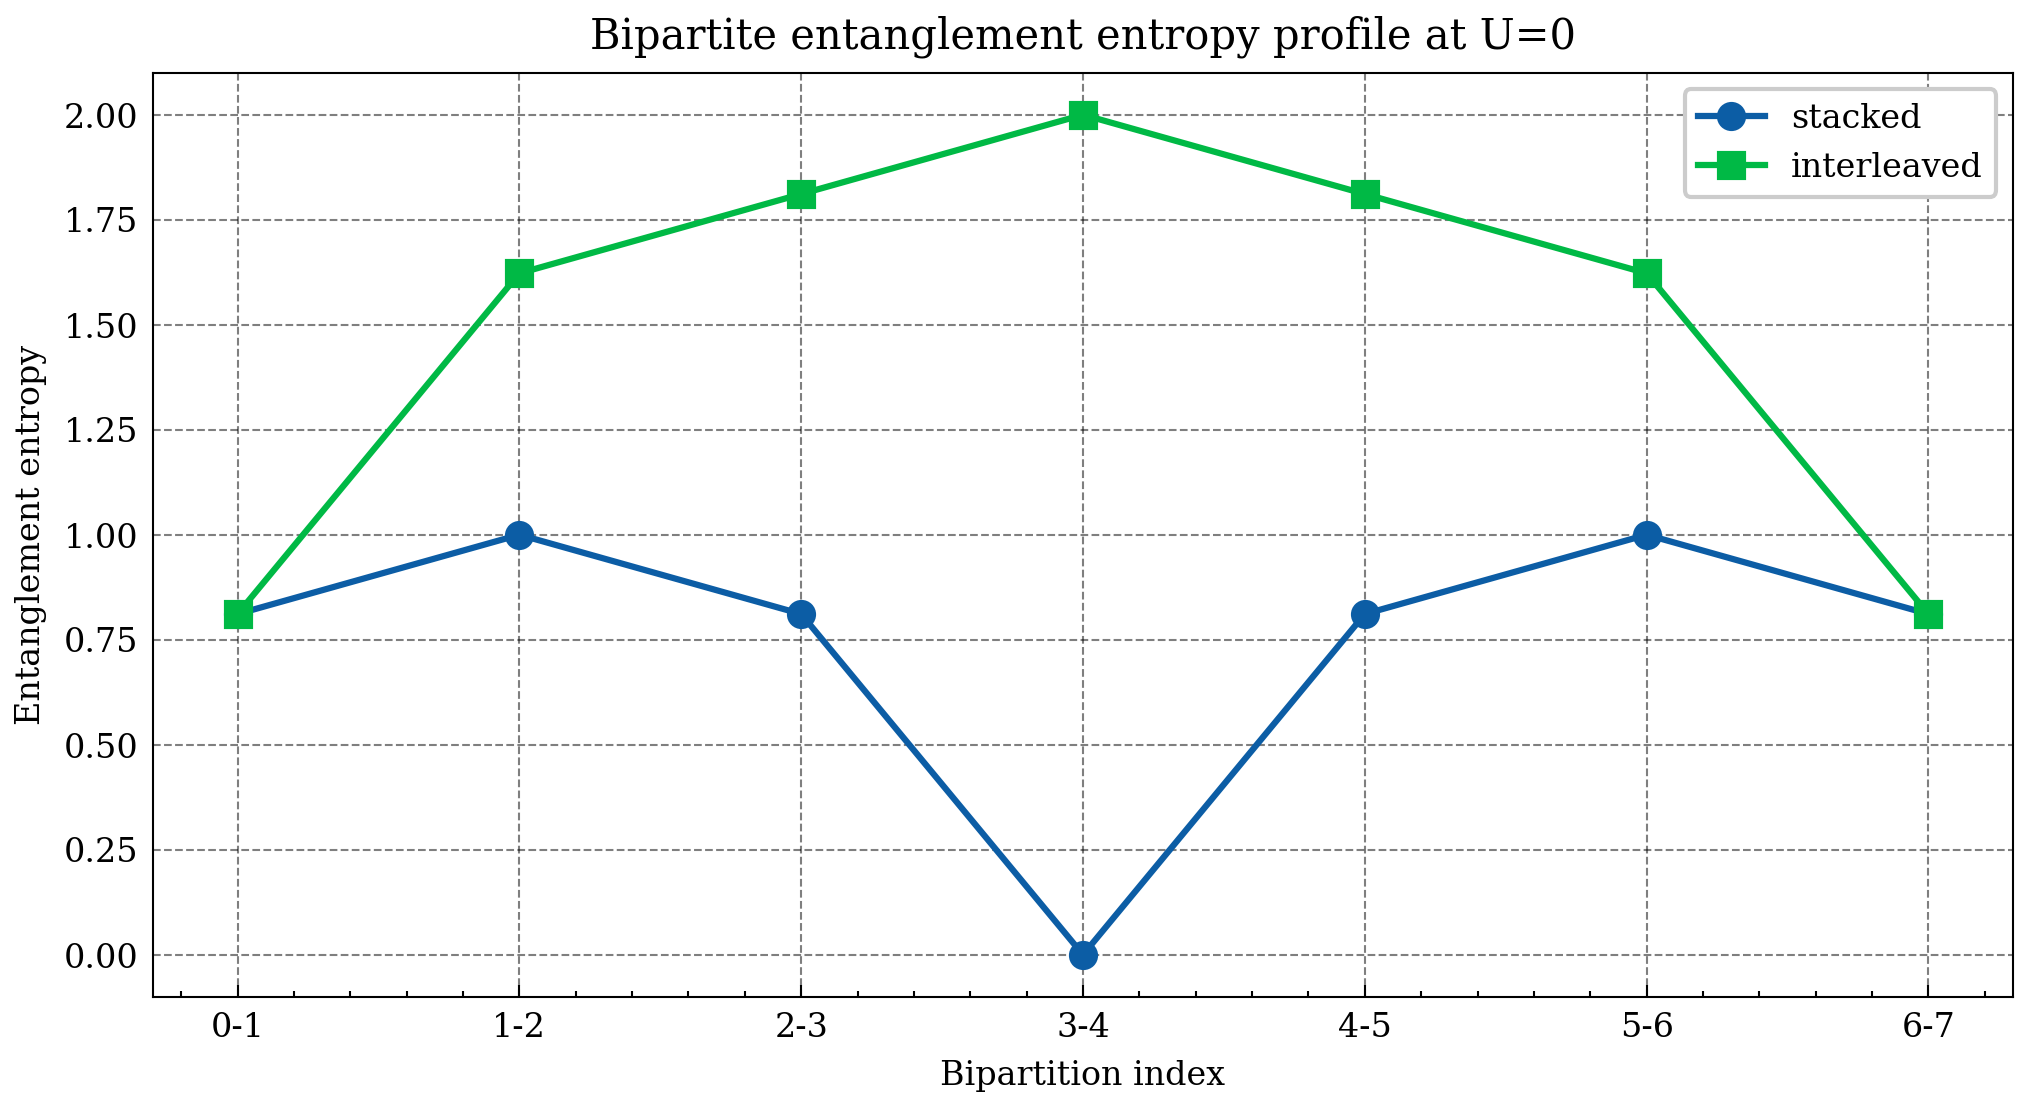

In [16]:
num_fermionic_sites = 4
t = 1.0
U = 0.0

fh = FermiHubbard1D(num_fermionic_sites=num_fermionic_sites, t=t, U=U, mu=0.0, periodic=True)
sv_s = fermionic_ground_state(fh, fh_encoding(num_fermionic_sites, "stacked"), 
                              fixed_spin_numbers=(1,1))
sv_i = fermionic_ground_state(fh, fh_encoding(num_fermionic_sites, "interleaved"), 
                              fixed_spin_numbers=(1,1))

profile_stacked = entanglement_profile(sv_s)
profile_interleaved = entanglement_profile(sv_i)

plt.figure(figsize=(8, 4))
plt.plot(range(len(profile_stacked)), np.array(profile_stacked), "o-", label="stacked")
plt.plot(range(len(profile_interleaved)), np.array(profile_interleaved), "s-", label="interleaved")
plt.xticks(range(len(profile_stacked)), [f"{i}-{i+1}" for i in range(len(profile_stacked))])
plt.xlabel("Bipartition index")
plt.ylabel("Entanglement entropy")
plt.title("Bipartite entanglement entropy profile at U=0")
plt.legend()